# Statistics & Chance: Rolling Dice 🎲
**Intro to Weather & Climate | Live classroom investigation**

**Learning goals:** distinguish theoretical and experimental probability; describe distributions; understand sampling variability and the law of large numbers; connect rare events to climate risk.

Run cells from top to bottom. Before each plot, ask students to **predict** what they will see. All simulations use fair, independent six-sided dice. Data are synthetic.

In [1]:
# These are imports
# run this cell, but you can ignore what it does for now
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from itertools import product

In [6]:

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})

def roll_sums(n_dice, n_rolls):
    return rng.integers(1, 7, size=(n_rolls, n_dice)).sum(axis=1)

def exact_probabilities(n_dice):
    counts = Counter(map(sum, product(range(1, 7), repeat=n_dice)))
    xs = np.arange(n_dice, 6*n_dice+1)
    return xs, np.array([counts[x]/6**n_dice for x in xs])

print("Ready! Change parameters in the cells below and rerun.")

Ready! Change parameters in the cells below and rerun.


## 1. One die: Does random mean evenly distributed?
**Predict:** If we roll a die 12 times, will each face appear exactly twice? Why or why not?

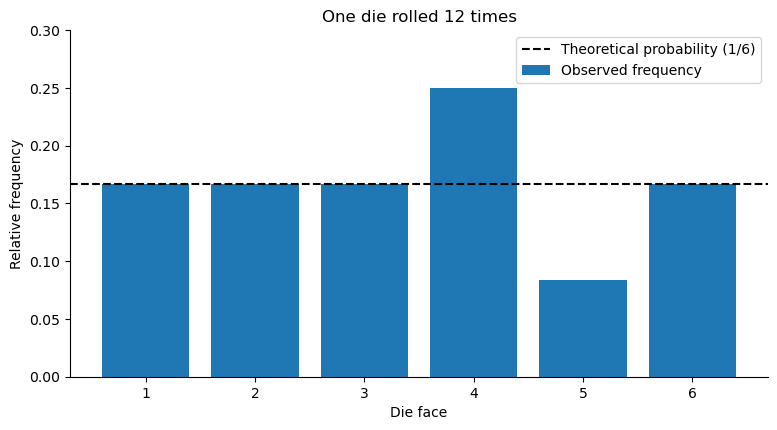

Number:  1 2 3 4 5 6
Counts: [2 2 2 3 1 2] | Mean: 3.417


In [88]:
# Change this value to see how the results change
n_rolls = 12  # Try 12, 60, 600, 6000

# this sets up the plot of the relative frequencies of rolling a single die n_rolls times
rolls = rng.integers(1, 7, size=n_rolls)
counts = np.bincount(rolls, minlength=7)[1:]
fig, ax = plt.subplots()
ax.bar(range(1,7), counts/n_rolls, label="Observed frequency")
ax.axhline(1/6, color="black", linestyle="--", label="Theoretical probability (1/6)")
ax.set(xlabel="Die face", ylabel="Relative frequency", title=f"One die rolled {n_rolls:,} times", xticks=range(1,7), ylim=(0,max(.3,1.15*max(counts/n_rolls))))
ax.legend(); plt.show()
print("Number:  1 2 3 4 5 6")
print("Counts:", counts, "| Mean:", round(rolls.mean(),3))

**Discuss:** Does a fair die guarantee equal counts? What changes when you increase the sample size? Does the *absolute number* of departures from expectation necessarily shrink?

## 2. Two dice: Why is 7 special?
**Predict:** Are sums 2 through 12 equally likely? List all pairs that produce a 7.

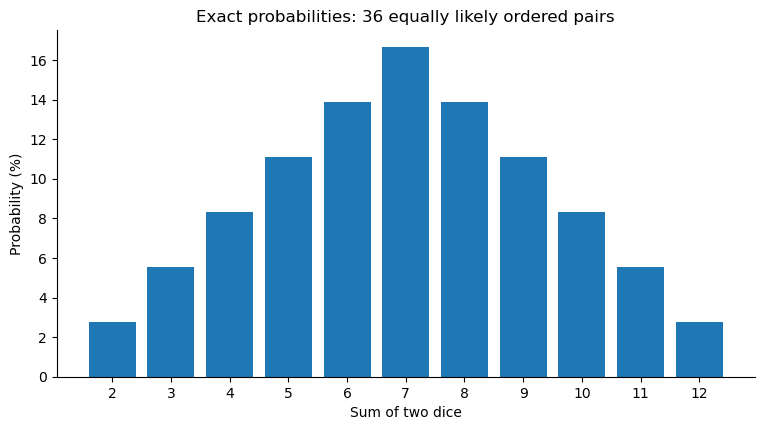

Pairs making 7: [(1, 6), (2, 5), (3, 4), (4, 3), (5, 2), (6, 1)]
P(sum=7) = 6/36 = 16.67 %
P(sum=2) = 1/36 = 2.78 %


In [100]:
pairs = np.array(list(product(range(1,7), repeat=2)))
possible_sums = pairs.sum(axis=1)
xs, probs = exact_probabilities(2)
fig, ax = plt.subplots()
ax.bar(xs, probs*100)
ax.set(xlabel="Sum of two dice", ylabel="Probability (%)", title="Exact probabilities: 36 equally likely ordered pairs", xticks=xs)
plt.show()
print("Pairs making 7:", [tuple(p.tolist()) for p in pairs[possible_sums==7]])
print("P(sum=7) = 6/36 =",round(100*6/36,2),"%")
print("P(sum=2) = 1/36 =",round(100/36,2),"%")

**Discuss:** The *individual dice* have uniform distributions, but their *sum* does not. Why?

## 3. Experiment versus theory
**Predict:** How close will the experimental frequencies be to the exact probabilities after 20, 200, or 20,000 rolls?

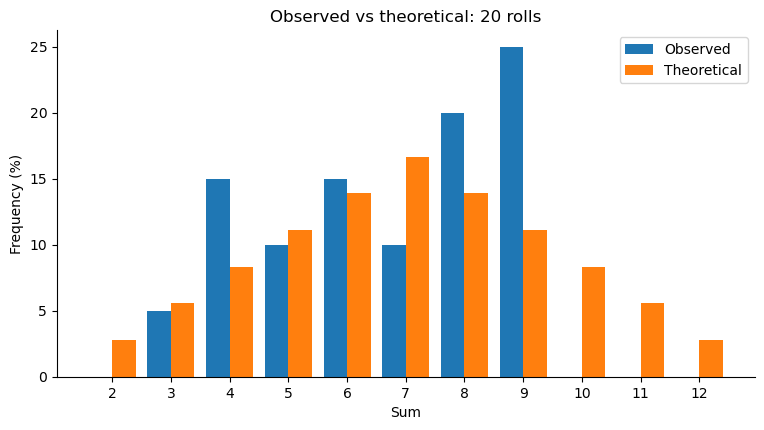

Observed P(7) = 10.0%; theoretical = 16.7%


In [28]:
n_rolls = 20  # Try 20, 200, 20000
sums = roll_sums(2, n_rolls)
observed = np.bincount(sums, minlength=13)[2:]/n_rolls
xs, theoretical = exact_probabilities(2)
fig, ax = plt.subplots()
ax.bar(xs-0.2, observed*100, width=0.4, label="Observed")
ax.bar(xs+0.2, theoretical*100, width=0.4, label="Theoretical")
ax.set(xlabel="Sum", ylabel="Frequency (%)", title=f"Observed vs theoretical: {n_rolls:,} rolls", xticks=xs)
ax.legend(); plt.show()
print(f"Observed P(7) = {100*np.mean(sums==7):.1f}%; theoretical = {100/6:.1f}%")

**Discuss:** Which is more predictable: a single outcome or the long-run proportion of outcomes?

## 4. More dice: The shape of a distribution
**Predict:** How does the distribution of sums change with 1, 2, 3, or 5 dice? Why does the center become more common?

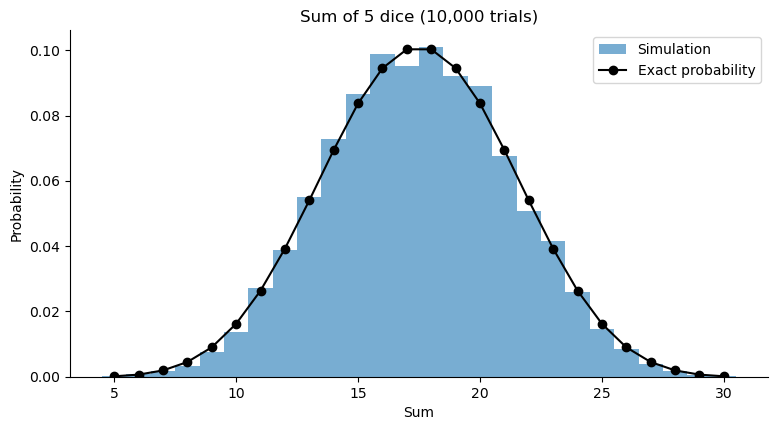

Theoretical mean of sum: 17.50; simulated mean: 17.48
Theoretical SD of sum: 3.82; simulated SD: 3.76


In [34]:
n_dice = 5  # Try 1, 2, 3, 5
n_rolls = 10000
sums = roll_sums(n_dice, n_rolls)
xs, theoretical = exact_probabilities(n_dice)
fig, ax = plt.subplots()
ax.hist(sums, bins=np.arange(n_dice-.5,6*n_dice+1.5), density=True, alpha=.6, label="Simulation")
ax.plot(xs, theoretical, "o-", color="black", label="Exact probability")
ax.set(xlabel="Sum", ylabel="Probability", title=f"Sum of {n_dice} dice ({n_rolls:,} trials)")
ax.legend(); plt.show()
print(f"Theoretical mean of sum: {3.5*n_dice:.2f}; simulated mean: {sums.mean():.2f}")
print(f"Theoretical SD of sum: {(n_dice*35/12)**.5:.2f}; simulated SD: {sums.std():.2f}")

**Instructor note:** This resembles the central limit theorem, but avoid claiming every climate variable is normally distributed. Precipitation and extremes often have skewed or heavy-tailed distributions. The **sum** spreads in absolute units as dice are added; the **average per die** becomes more concentrated.

## 5. Law of large numbers: Watch the estimate settle
**Predict:** Will the running fraction of sums equal to 7 ever become exactly 1/6?

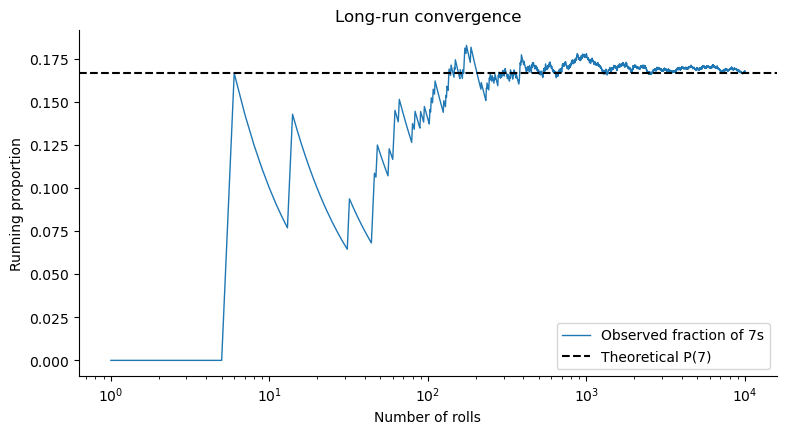

In [47]:
n_rolls = 10000
sums = roll_sums(2, n_rolls)
running_p = np.cumsum(sums==7)/np.arange(1,n_rolls+1)
fig, ax = plt.subplots()
ax.plot(np.arange(1,n_rolls+1), running_p, lw=1, label="Observed fraction of 7s")
ax.axhline(1/6, color="black", linestyle="--", label="Theoretical P(7)")
ax.set(xlabel="Number of rolls", ylabel="Running proportion", title="Long-run convergence", xscale="log")
ax.legend(); plt.show()

**Discuss:** Does the law of large numbers mean a 7 is "due" after several non-7 rolls? **No:** each new roll remains independent.

## 6. Rare events: How often is *at least one* likely?
Define a rare event as rolling **two sixes** in one two-dice trial: probability 1/36.

**Predict:** Across 30 independent trials, is it more likely than not that you see at least one double-six?

Exact chance of >=1 double-six in 25 trials: 50.6%
Simulated chance across 10,000 experiments: 50.9%


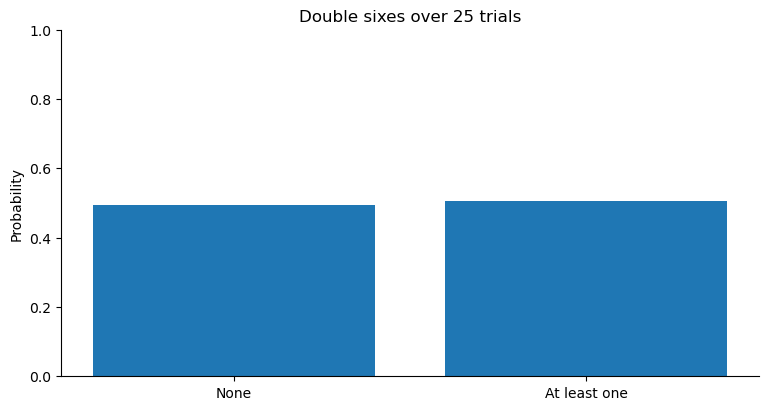

In [75]:
p = 1/36
n_trials = 25  # Try 1, 10, 30, 100
exact_at_least_one = 1-(1-p)**n_trials
n_experiments = 10000
trials = rng.integers(1,7,size=(n_experiments,n_trials,2))
event = np.all(trials==6,axis=2)
simulated = np.mean(event.any(axis=1))
print(f"Exact chance of >=1 double-six in {n_trials} trials: {exact_at_least_one:.1%}")
print(f"Simulated chance across {n_experiments:,} experiments: {simulated:.1%}")
fig,ax=plt.subplots()
ax.bar(["None", "At least one"], [1-exact_at_least_one, exact_at_least_one])
ax.set(ylabel="Probability",ylim=(0,1),title=f"Double sixes over {n_trials} trials")
plt.show()

**Climate connection:** A 1% annual-chance flood does not occur on a schedule. Under the simplifying assumptions of independent years and constant annual risk, the probability of at least one such event in 30 years is `1 - (0.99)**30`, about 26%. Real climate hazards may violate these assumptions, and their probabilities can change over time. 

Check out **100-year flood** in [FEMA's Glossary](https://training.fema.gov/is/course/glossary.aspx) if you are stil curious. 

In [78]:
annual_probability = 0.01
years = 30
print(f"Chance of at least one event in {years} years: {1-(1-annual_probability)**years:.1%}")

Chance of at least one event in 30 years: 26.0%


## 7. A changing climate: What if the dice change?
Imagine a hypothetical system in which a "hot event" occurs when the sum of two dice is **10 or greater**. Change the chance of rolling a six on *each die*, distributing the remaining probability equally among faces 1–5. This is an **analogy**, not a physical model of temperature.

**Predict:** How much does the chance of a hot event change?

Baseline P(sum >= 10): 16.7%
Modified P(sum >= 10): 16.7%
Risk ratio: 1.00x


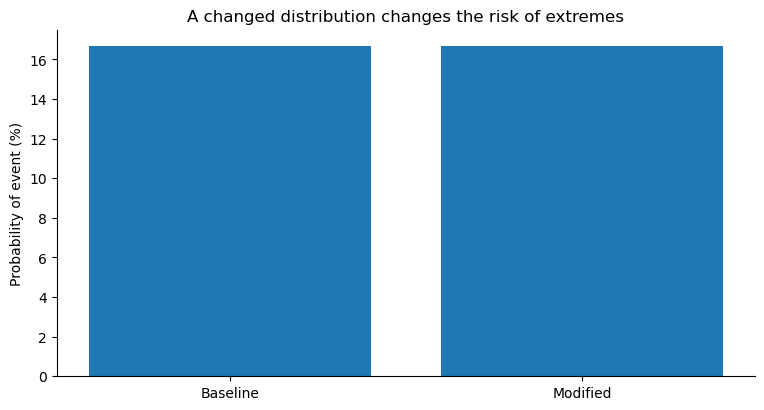

In [82]:
p_six = 1/6  # Try 1/6, 0.25, 0.35
face_probs = np.array([(1-p_six)/5]*5+[p_six])
all_pairs = np.array(list(product(range(1,7),repeat=2)))
pair_prob = face_probs[all_pairs[:,0]-1]*face_probs[all_pairs[:,1]-1]
prob_hot = pair_prob[all_pairs.sum(axis=1)>=10].sum()
base_prob = np.mean(all_pairs.sum(axis=1)>=10)
print(f"Baseline P(sum >= 10): {base_prob:.1%}")
print(f"Modified P(sum >= 10): {prob_hot:.1%}")
print(f"Risk ratio: {prob_hot/base_prob:.2f}x")
fig,ax=plt.subplots()
ax.bar(["Baseline", "Modified"],[base_prob*100,prob_hot*100])
ax.set(ylabel="Probability of event (%)",title="A changed distribution changes the risk of extremes")
plt.show()

**Discuss:** Did we change the definition of the extreme event, or its probability? How is this like comparing extreme heat under two different climates?

## Exit ticket (3 minutes)
1. Why is 7 more common than 2 when rolling two dice?
2. Why can 20 rolls disagree substantially with theoretical probabilities?
3. Does a 1-in-100 annual chance event happen only once every 100 years?
4. How can a shift in a distribution change the frequency of extremes?

**Instructor quick answers:** (1) Six combinations versus one. (2) Sampling variability. (3) No; each year has an annual probability, under stationarity. (4) More probability mass may cross a fixed threshold.

**Extension:** Discuss the limitations of assuming independent, identically distributed trials when analyzing real climate observations.